# 07 · Regla de decisión: de señal a investigar a candidato después de costos

> **Ningún aviso de este notebook es una oportunidad confirmada.** Hay dos niveles: **señal a investigar** (la lista
> oficial: el precio publicado está muy por debajo del esperado) y **candidato después de costos** (además, comprarlo,
> refaccionarlo y venderlo deja margen con costos realistas). Los dos dependen del precio esperado, que tiene error,
> y de supuestos de costos. El paso siguiente siempre es que un analista revise el aviso.

**Qué resuelve.** La brecha compara precios publicados. Al fondo le importa otra cosa: si, después de pagar la compra,
la obra y la venta, queda margen. La regla traduce la señal en un resultado económico y deja afuera las señales que
no cierran (por costos o por riesgo legal). Responde a la devolución de la PreEntrega 2, que pedía incorporar costos
de refacción, liquidez, estado y riesgo legal en una regla de decisión.

**La regla** (`src/regla.py`, aplicada en la etapa 6; costos en `config/costos.yaml`, con fuente cada uno):

- **Costo total** = precio publicado + costos de entrada + refacción.
  - Se compra **al precio publicado**: un aviso ya barato deja poco margen para negociar (supuesto conservador).
  - Entrada: escribano (con su honorario mínimo), la mitad del impuesto de Sellos (2,7% del total hasta USD 148.941
    y 3,5% por encima), comisión del comprador y gastos de escritura (8,8% en el escenario base).
  - Refacción según el estado del título: liviana (pintura y pisos, USD 105 por m²) en los avisos sin marca, media
    (baño, cocina y liviana) en los "a refaccionar", integral (USD 1.227 por m²) en los "a reciclar", ninguna en los
    "a estrenar" y "ya reformado".
- **Venta neta** = valor de salida × (1 − negociación) − costos de salida.
  - **Valor de salida:** el valor esperado del modelo. Si el aviso se refacciona (media o integral), sin la prima
    negativa de su estado (se compra "a reciclar" y se vende reciclado).
  - Se vende **a precio de cierre**, no al publicado: 4,79% por debajo (UCEMA). Supuesto conservador.
  - Salida: comisión del vendedor, su mitad de Sellos y certificados (supuestos agregados a `costos.yaml`).
- **Brecha neta** = (venta neta − Ganancias − costo total) / costo total. En el escenario base va **antes del
  impuesto a las ganancias**, porque depende de la forma jurídica del fondo, que no conocemos; la sensibilidad
  muestra 15% y 35%.
- **Candidato después de costos:** señal a investigar con brecha neta de al menos **+10%** (margen de seguridad
  frente al error del modelo) y sin señales de riesgo legal de descarte (nuda propiedad, en pozo, sin escritura,
  parte indivisa). Las de "revisar" (con inquilino, con financiación) pasan con una alerta.
- **Liquidez:** la tasa de salida del portal por ambientes (notebook 06: alcanza con las ambientes) es informativa,
  para ordenar y para la ficha; no filtra.

**Qué agrega frente a la alternativa simple.** La alternativa es la lista oficial sola, o restarle a la brecha un
costo fijo (por ejemplo, 8,8% de entrada). La regla agrega lo que cambia de aviso a aviso: el umbral de Sellos, el
honorario mínimo del escribano en avisos chicos, la obra según el estado y su tamaño, y el valor recuperable al
refaccionar.

**Límites.**
- **Costo de tenencia: no está incluido.** Mientras el departamento está en obra o en venta, el fondo paga expensas
  (y ABL) y tiene el capital inmovilizado: con un tiempo de venta de 8,8 meses en promedio (costos.yaml, liquidez),
  es un costo real que la brecha neta no descuenta.
- El precio esperado tiene un error mediano de 12,5%; por eso el umbral de +10% y el escenario que usa el límite
  inferior del intervalo del 80%.
- El estado sale del título del aviso; un aviso sin marca puede necesitar más obra de la que dice.
- La prima de estado del modelo es una asociación: se supone que refaccionar recupera exactamente esa prima.
- Ganancias depende de la estructura del fondo; los costos de salida son supuestos con fuente, no cotizaciones.

## 1. Configuración e ingesta

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import regla, validacion
from src.configuracion import cargar_config
from src.eda import AZUL, AZUL_OSCURO, GRIS, ROJO

CFG = cargar_config()
UMBRAL = CFG["analisis"]["umbral_brecha_neta"]
costos = validacion.cargar_reglas_titulo()
avisos = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t", low_memory=False)
for col in ["riesgo_descartar", "riesgo_revisar", "motivo_decision", "nivel_decision"]:
    avisos[col] = avisos[col].fillna("")
embudo = pd.read_csv(RAIZ / CFG["rutas"]["embudo"])
# Las primas de estado que usó la etapa 6 (coeficientes del lineal ampliado, promedio de las vueltas)
primas = avisos.groupby("estado_titulo")["prima_estado"].first().to_dict()
senales = avisos[avisos["cumple_regla"]].copy()
print(f"Señales a investigar: {len(senales):,} avisos | {senales['unidad'].nunique():,} unidades")
print("Primas de estado (log):", {k: round(v, 3) for k, v in primas.items()})
embudo[["filtro", "avisos", "unidades", "unidades_%_del_paso_anterior"]]

Señales a investigar: 1,443 avisos | 1,362 unidades
Primas de estado (log): {'a_estrenar': 0.025, 'a_reciclar': -0.198, 'a_refaccionar': -0.166, 'sin_marca': 0.0, 'ya_reformado': 0.081}


,filtro,avisos,unidades,unidades_%_del_paso_anterior
0,Avisos del dataset limpio,27578,25168,NaN
1,Brecha menor que el umbral de la ciudad (−25%),1800,1695,6.7
2,"Además, por debajo del umbral según el error d...",1546,1459,86.1
3,"Además, sin señales de error de carga (regla R...",1443,1362,93.4
4,"Además, brecha neta de costos sobre el umbral ...",885,839,61.6


## 2. La regla en un aviso

Para ver cómo se arma la brecha neta, el candidato mediano: el que tiene la brecha neta más cercana a la mediana de
los candidatos.

la-boca | 60 m² | estado: sin_marca | refacción: liviana | brecha -37% | brecha neta 18%


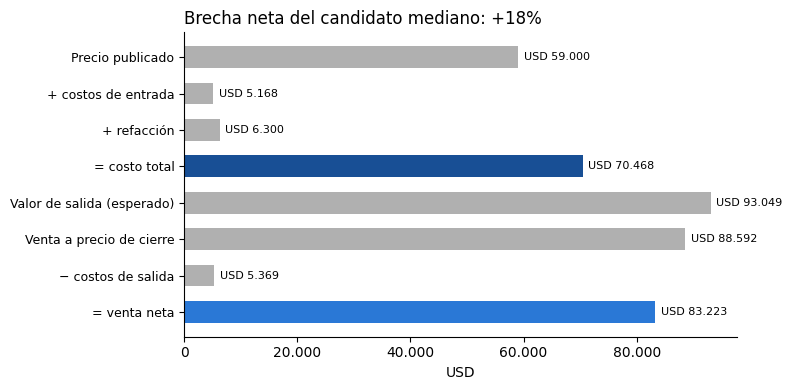

In [2]:
candidatos = senales[senales["candidato"]]
ejemplo = candidatos.loc[(candidatos["brecha_neta"] - candidatos["brecha_neta"].median()).abs().idxmin()]
print(f"{ejemplo['barrio']} | {ejemplo['m2_final']:.0f} m² | estado: {ejemplo['estado_titulo']} | refacción: "
      f"{ejemplo['nivel_refaccion']} | brecha {100 * ejemplo['brecha']:.0f}% | brecha neta {100 * ejemplo['brecha_neta']:.0f}%")
pasos = {
    "Precio publicado": ejemplo["precio_usd"],
    "+ costos de entrada": ejemplo["costo_entrada_usd"],
    "+ refacción": ejemplo["refaccion_usd"],
    "= costo total": ejemplo["costo_total_usd"],
    "Valor de salida (esperado)": ejemplo["valor_salida_usd"],
    "Venta a precio de cierre": ejemplo["venta_cierre_usd"],
    "− costos de salida": ejemplo["costo_salida_usd"],
    "= venta neta": ejemplo["venta_cierre_usd"] - ejemplo["costo_salida_usd"],
}
fig, ax = plt.subplots(figsize=(8, 4))
colores = [GRIS, GRIS, GRIS, AZUL_OSCURO, GRIS, GRIS, GRIS, AZUL]
ax.barh(range(len(pasos))[::-1], list(pasos.values()), color=colores, height=0.6)
for i, (nombre, valor) in enumerate(pasos.items()):
    ax.text(valor + 1000, len(pasos) - 1 - i, f"USD {valor:,.0f}".replace(",", "."), va="center", fontsize=8)
ax.set_yticks(range(len(pasos))[::-1], list(pasos.keys()), fontsize=9)
ax.set_xlabel("USD")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_title(f"Brecha neta del candidato mediano: {100 * ejemplo['brecha_neta']:+.0f}%", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

## 3. Cuántas señales pasan a candidato y por qué no pasan las demás

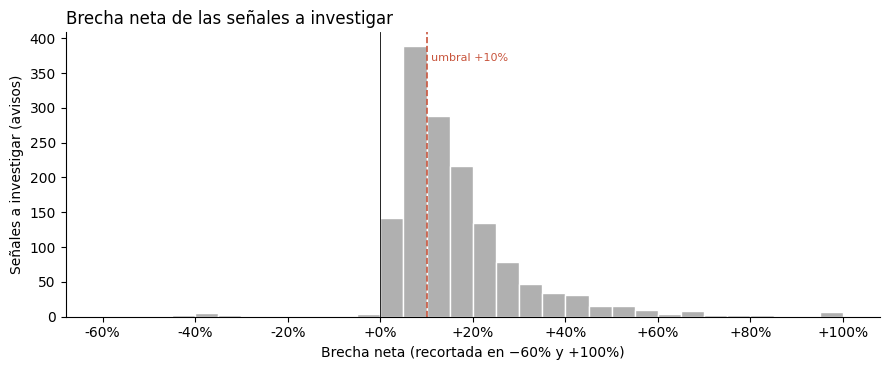

col_0,brecha neta bajo el umbral,candidato después de costos,riesgo legal de descarte,total
nivel_refaccion,,,,
integral,12,1,0,13
liviana,528,817,14,1359
media,2,5,0,7
ninguna,2,62,0,64
total,544,885,14,1443


In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.arange(-0.6, 1.01, 0.05)
ax.hist(senales["brecha_neta"].clip(-0.6, 1.0), bins=bordes, color=GRIS, edgecolor="white")
ax.axvline(UMBRAL, color=ROJO, lw=1.2, ls="--")
ax.text(UMBRAL + 0.01, ax.get_ylim()[1] * 0.9, f"umbral +{100 * UMBRAL:.0f}%", color=ROJO, fontsize=8)
ax.axvline(0, color="black", lw=0.6)
ax.set_xticks(np.arange(-0.6, 1.01, 0.2), [f"{100 * x:+.0f}%" for x in np.arange(-0.6, 1.01, 0.2)])
ax.set_xlabel("Brecha neta (recortada en −60% y +100%)")
ax.set_ylabel("Señales a investigar (avisos)")
ax.set_title("Brecha neta de las señales a investigar", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

motivo = np.where(senales["candidato"], "candidato después de costos",
                  np.where(senales["riesgo_descartar"] != "", "riesgo legal de descarte", "brecha neta bajo el umbral"))
pd.crosstab(senales["nivel_refaccion"], motivo, margins=True, margins_name="total")

In [4]:
# Brecha neta por nivel de refacción: la obra integral (reciclar) casi nunca cierra
senales.groupby("nivel_refaccion").agg(
    avisos=("brecha_neta", "size"), brecha_mediana_pct=("brecha", lambda b: 100 * b.median()),
    brecha_neta_mediana_pct=("brecha_neta", lambda b: 100 * b.median()),
    candidatos_pct=("candidato", lambda c: 100 * c.mean())).round(1)

,avisos,brecha_mediana_pct,brecha_neta_mediana_pct,candidatos_pct
nivel_refaccion,,,,
integral,13,-31.3,-37.3,7.7
liviana,1359,-31.5,12.3,60.1
media,7,-34.5,17.2,71.4
ninguna,64,-30.7,18.3,96.9


> **Interpretación:** _(a completar)_

## 4. Sensibilidad

¿Cuántas unidades quedan como candidatas si cambian los supuestos? Se mueve un supuesto por vez desde el escenario
base, y al final se cruzan escenario y umbral. Una unidad es candidata si al menos uno de sus avisos lo es (como en el
ranking).
- **Costos:** optimista (mínimos de `costos.yaml`) y pesimista (máximos; el comprador paga todo Sellos).
- **Refacción:** el nivel bajo y el alto de `nivel_sensibilidad` para cada estado.
- **Valor de salida conservador:** el límite inferior del intervalo del 80% en lugar del precio esperado.
- **Ganancias:** el escenario base **no descuenta el impuesto a las ganancias (alícuota 0)**, porque depende de la
  forma jurídica del fondo, que no conocemos: la brecha neta base es antes de impuestos. Acá se muestra con 15% (régimen
  cedular) y 35% (escala de sociedades). El simulador del dashboard permite elegir 0, 15 o 35%.
- **Umbral:** 0% y +20%.

In [5]:
def unidades_candidatas(escenario="base", refaccion="central", valor_salida="esperado", ganancias=None,
                        umbral=UMBRAL):
    calculo = regla.calcular(senales, primas, costos, escenario, refaccion, valor_salida, ganancias)
    candidato, _, _ = regla.decidir(senales["cumple_regla"], calculo["brecha_neta"], senales["riesgo_descartar"],
                                    umbral)
    return int(senales.loc[candidato, "unidad"].nunique())


total = senales["unidad"].nunique()
variantes = {
    "base": {},
    "costos optimistas": {"escenario": "optimista"},
    "costos pesimistas": {"escenario": "pesimista"},
    "refacción baja": {"refaccion": "baja"},
    "refacción alta": {"refaccion": "alta"},
    "salida: límite inferior del 80%": {"valor_salida": "limite_inferior"},
    "Ganancias 15%": {"ganancias": 0.15},
    "Ganancias 35%": {"ganancias": 0.35},
    "umbral 0%": {"umbral": 0.0},
    "umbral +20%": {"umbral": 0.20},
}
sensibilidad = pd.DataFrame({nombre: {"unidades_candidatas": unidades_candidatas(**kw)} for nombre, kw in variantes.items()}).T
sensibilidad["%_de_las_señales"] = (100 * sensibilidad["unidades_candidatas"] / total).round(1)
assert sensibilidad.loc["base", "unidades_candidatas"] == avisos.loc[avisos["candidato"], "unidad"].nunique()
sensibilidad

,unidades_candidatas,%_de_las_señales
base,839,61.6
costos optimistas,1331,97.7
costos pesimistas,523,38.4
refacción baja,1304,95.7
refacción alta,365,26.8
salida: límite inferior del 80%,84,6.2
Ganancias 15%,726,53.3
Ganancias 35%,545,40.0
umbral 0%,1335,98.0
umbral +20%,366,26.9


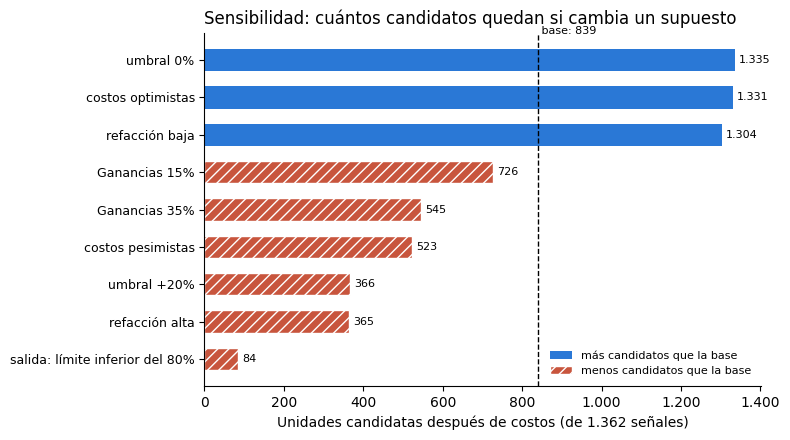

In [6]:
base = sensibilidad.loc["base", "unidades_candidatas"]
resto = sensibilidad.drop("base").sort_values("unidades_candidatas")
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(resto))
menos = (resto["unidades_candidatas"] < base).values
ax.barh(pos[~menos], resto["unidades_candidatas"][~menos], color=AZUL, height=0.6, label="más candidatos que la base")
ax.barh(pos[menos], resto["unidades_candidatas"][menos], color=ROJO, hatch="///", edgecolor="white", height=0.6,
        label="menos candidatos que la base")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.axvline(base, color="black", lw=1, ls="--")
ax.text(base, len(resto) - 0.3, f" base: {base:,}".replace(",", "."), fontsize=8)
for i, v in enumerate(resto["unidades_candidatas"]):
    ax.text(v + 10, i, f"{v:,}".replace(",", "."), va="center", fontsize=8)
ax.set_yticks(pos, resto.index, fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_xlabel(f"Unidades candidatas después de costos (de {total:,} señales)".replace(",", "."))
ax.set_title("Sensibilidad: cuántos candidatos quedan si cambia un supuesto", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
# Escenario de costos × umbral, con el valor de salida esperado y con el límite inferior del 80%
filas = []
for salida in ["esperado", "limite_inferior"]:
    for escenario in ["optimista", "base", "pesimista"]:
        fila = {"valor de salida": salida, "costos": escenario}
        for umbral in [0.0, 0.10, 0.20]:
            fila[f"umbral {100 * umbral:+.0f}%"] = unidades_candidatas(escenario, valor_salida=salida, umbral=umbral)
        filas.append(fila)
pd.DataFrame(filas).set_index(["valor de salida", "costos"])

umbral +0%  umbral +10%  umbral +20%
valor de salida costos                                         
esperado        optimista        1339         1331          747
                base             1335          839          366
                pesimista        1174          523          213
limite_inferior optimista         404          162           83
                base              193           84           35
                pesimista         117           51           23

> **Interpretación:** _(a completar)_

## 5. Liquidez de los candidatos (informativa)

La tasa de salida del portal entre relevamientos, por ambientes, sin barrios truncados (notebook 05, sección 2.2, y
notebook 06). No filtra: ayuda a ordenar y se muestra en la ficha. Salir del portal no es lo mismo que venderse.

In [8]:
limpio = pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False, usecols=["id_aviso", "ambientes", "dormitorios"])
ambientes = limpio.set_index("id_aviso").loc[candidatos["id_aviso"]]
grupo = ambientes["ambientes"].fillna(ambientes["dormitorios"] + 1).clip(1, 5).astype(int).map(
    lambda a: f"{a} amb." if a < 5 else "5 amb. o más").values
candidatos.assign(ambientes=grupo).groupby("ambientes").agg(
    candidatos=("id_aviso", "size"), tasa_salida_pct=("tasa_salida_ambientes", lambda t: 100 * t.iloc[0]),
    brecha_neta_mediana_pct=("brecha_neta", lambda b: 100 * b.median())).round(1)

,candidatos,tasa_salida_pct,brecha_neta_mediana_pct
ambientes,,,
1 amb.,144,41.4,16.4
2 amb.,173,43.0,16.7
3 amb.,214,39.8,18.1
4 amb.,186,37.8,19.3
5 amb. o más,168,31.2,21.1


## 6. Alertas de riesgo legal

Las señales con riesgo de "descartar" no llegan a candidato; las de "revisar" pasan con una alerta para el analista.

In [9]:
pd.DataFrame({
    "descartar (señales)": senales["riesgo_descartar"].str.split(", ").explode().loc[lambda s: s != ""].value_counts(),
    "revisar (candidatos con alerta)": candidatos["riesgo_revisar"].str.split(", ").explode().loc[
        lambda s: s != ""].value_counts(),
}).fillna(0).astype(int)

,descartar (señales),revisar (candidatos con alerta)
con financiacion,0,10
con inquilino,0,6
en pozo,9,0
nuda propiedad,3,0
parte indivisa,1,0
sin escritura,1,0


> **Interpretación:** _(a completar)_